# DRRF – Mục 5: Chạy thực nghiệm mô hình đề xuất rebate
**Nhóm 15 – Phân tích dữ liệu (UEH)**

Notebook chạy lại toàn bộ kết quả của mục 5 trên `dataset_cement_cust.xlsx` (240 NPP × 21 cột):

| Bước | Nội dung | Mục báo cáo |
|---|---|---|
| A | Sàng lọc biến đầu vào (Pearson, VIF) | 5.2 |
| B | Tầng 1 – Phân cụm K-Means, chọn k | 5.3 |
| C | Chuẩn hóa 3 hướng, trọng số AHP, Rebate Score, quy đổi VNĐ/tấn | 5.4 |
| D | Tầng 2 – Chia dữ liệu 80/20 + 5-fold CV, tinh chỉnh, so sánh 3 mô hình, tập kiểm tra | 5.5 |
| E | Diễn giải mô hình, đối chiếu AHP | 5.5.5 |
| F | Ngân sách, 10 NPP điển hình, xuất file | 5.6 |
| G | Kiểm tra độ nhạy theo chiều chuẩn hóa | 5.7 |

**Cách dùng:** `Runtime → Run all`. Ô ở Bước 0 sẽ yêu cầu tải file `dataset_cement_cust.xlsx` lên. Toàn bộ chạy mất khoảng 5–8 phút (phần lâu nhất là tinh chỉnh Random Forest ở Bước D). `random_state = 42` cố định nên kết quả trùng với báo cáo.

**Hình ảnh:** 6 biểu đồ (Hình 5.1–5.6, giống trong báo cáo) được tự động lưu dạng PNG (200 dpi) vào thư mục con `hinh_anh_muc5_need/` (hoặc `hinh_anh_muc5_health/` khi đổi MODE), nằm cùng thư mục với notebook.

## Bước 0 – Cài đặt, import và tải dữ liệu

In [20]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
SEED = 42
rng = np.random.default_rng(SEED)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

# ---- Định dạng biểu đồ & hàm lưu hình vào thư mục con ----
import os, matplotlib.ticker as mtick
BLUE, ORANGE, GRAY, INK = "#2E5C8A", "#C8743A", "#9AA3AD", "#1F2933"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#E6E9EC",
                     "axes.axisbelow": True, "axes.edgecolor": "#C9CED4"})
VN = mtick.FuncFormatter(lambda x, p: f"{x:,.0f}".replace(",", "."))   # 3.000 thay vì 3,000
def save_fig(fig, name):
    folder = f"hinh_anh_muc5_{MODE}"
    os.makedirs(folder, exist_ok=True)
    path = os.path.join(folder, name + ".png")
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print("Đã lưu hình:", path)

In [21]:
# Tải file dữ liệu lên Colab (hoặc đặt sẵn file cùng thư mục với notebook khi chạy trên máy)
DATA = "dataset_cement_cust.xlsx"
try:
    from google.colab import files
    up = files.upload()            # chọn file dataset_cement_cust.xlsx
    DATA = list(up.keys())[0]
except ImportError:
    pass                            # không chạy trên Colab -> đọc file ở thư mục hiện tại
df = pd.read_excel(DATA)
print(df.shape)
print("Giá trị thiếu:", int(df.isna().sum().sum()), "| Dòng trùng:", int(df.duplicated().sum()))
df.head()

(240, 21)
Giá trị thiếu: 0 | Dòng trùng: 0


,NPP_ID,Tinh_Thanh,Vung_Mien,Loai_NPP,Doanh_so_12_thang_tan,So_diem_ban,Do_phu_thi_truong_pct,Gia_ban_trung_binh_NPP_VND_tan,Gia_TB_thi_truong_khu_vuc_VND_tan,Price_Index,Cuong_do_canh_tranh_1_5,Bien_loi_nhuan_gop_NPP_pct,Bien_loi_nhuan_TB_doi_thu_pct,Profitability_Gap_pct,So_nam_hop_tac,Share_of_Wallet_pct,Tang_truong_YoY_pct,Diem_du_an_ha_tang_khu_vuc_1_5,Vong_quay_ton_kho_ngay,Ty_le_cong_no_qua_han_pct,Muc_rebate_hien_tai_VND_tan
0,NPP_001,Vĩnh Long,Tây Nam Bộ (ĐBSCL),Nhà phân phối cấp 1,24988,50,15.2,1531000,1550000,0.988,3.5,5.96,9.45,-3.49,5.7,53.2,23.4,3.6,16.2,11.7,54000
1,NPP_002,Tây Ninh,Đông Nam Bộ,Tổng đại lý,21271,39,20.9,1475000,1475000,1.000,3.7,8.72,10.16,-1.44,13.6,67.9,22.9,3.9,26.5,3.7,46000
2,NPP_003,Vĩnh Long,Tây Nam Bộ (ĐBSCL),Tổng đại lý,25453,49,47.4,1587000,1577000,1.006,2.9,11.83,10.11,1.72,9.5,51.5,8.0,2.5,17.6,5.0,63000
3,NPP_004,Sóc Trăng,Tây Nam Bộ (ĐBSCL),Tổng đại lý,18315,44,26.2,1593000,1563000,1.019,1.0,12.09,8.32,3.77,1.8,29.9,12.6,3.0,20.0,9.0,47000
4,NPP_005,Bình Phước,Đông Nam Bộ,Nhà phân phối cấp 1,44344,74,49.8,1486000,1502000,0.989,3.1,8.37,8.66,-0.29,12.2,35.3,21.3,4.9,18.5,10.4,68000


**Tùy chọn chiều chuẩn hóa** – `MODE = "need"` là phiên bản chính thức (Profitability Gap = cost, Cường độ cạnh tranh = benefit: điểm cao = cần hỗ trợ nhiều). Đổi thành `"health"` để chạy đúng nhãn Bảng 4.1 bài giữa kỳ (dùng cho kiểm tra độ nhạy ở Bước G).

In [22]:
MODE = "need"
TARGET_RAW = "Muc_rebate_hien_tai_VND_tan"   # rebate hiện tại: KHÔNG làm đầu vào, KHÔNG làm nhãn

## Bước A – Sàng lọc biến đầu vào (mục 5.2)
Mục tiêu: loại các biến đo trùng một khái niệm để tránh "đếm hai lần" trong khoảng cách K-Means và làm hệ số hồi quy mất ổn định. Ngưỡng theo mục 4.4.2: **|r Pearson| > 0,8** hoặc **VIF > 5**, với VIF = 1 / (1 − R²) khi hồi quy một biến theo tất cả biến còn lại.

In [23]:
cand = [c for c in df.select_dtypes("number").columns if c != TARGET_RAW]   # 16 biến ứng viên

def vif_table(X):
    out = {}
    for c in X.columns:
        o = X.drop(columns=c)
        r2 = LinearRegression().fit(o, X[c]).score(o, X[c])
        out[c] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False).round(2)

corr = df[cand].corr()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(cand) for b in cand[i+1:] if abs(corr.loc[a, b]) > 0.8]
print("Các cặp |r| > 0,8:"); [print("  ", p) for p in pairs]
print("\nVIF ban đầu (16 biến):"); print(vif_table(df[cand]))

Các cặp |r| > 0,8:
   ('Doanh_so_12_thang_tan', 'So_diem_ban', np.float64(0.945))
   ('Gia_ban_trung_binh_NPP_VND_tan', 'Gia_TB_thi_truong_khu_vuc_VND_tan', np.float64(0.866))
   ('Bien_loi_nhuan_gop_NPP_pct', 'Profitability_Gap_pct', np.float64(0.893))

VIF ban đầu (16 biến):
Bien_loi_nhuan_gop_NPP_pct               inf
Bien_loi_nhuan_TB_doi_thu_pct            inf
Profitability_Gap_pct                    inf
Gia_ban_trung_binh_NPP_VND_tan       5899.42
Gia_TB_thi_truong_khu_vuc_VND_tan    3214.54
Price_Index                          1559.78
Doanh_so_12_thang_tan                  11.06
So_diem_ban                            10.13
Cuong_do_canh_tranh_1_5                 3.38
Tang_truong_YoY_pct                     2.44
Diem_du_an_ha_tang_khu_vuc_1_5          2.38
Do_phu_thi_truong_pct                   1.58
Share_of_Wallet_pct                     1.44
So_nam_hop_tac                          1.37
Ty_le_cong_no_qua_han_pct               1.08
Vong_quay_ton_kho_ngay                  1.07
dt

In [24]:
# Loại theo |r| > 0,8: giữ chỉ số kinh doanh trực tiếp / chỉ số dẫn xuất
drop_stat = ["So_diem_ban", "Gia_ban_trung_binh_NPP_VND_tan", "Bien_loi_nhuan_gop_NPP_pct"]
# Loại 2 biến benchmark thị trường vì đã nằm sẵn trong Price_Index và Profitability_Gap
drop_concept = ["Gia_TB_thi_truong_khu_vuc_VND_tan", "Bien_loi_nhuan_TB_doi_thu_pct"]
FEATS11 = [c for c in cand if c not in drop_stat + drop_concept]
print(len(FEATS11), "biến đầu vào:", FEATS11)
print(vif_table(df[FEATS11]))      # kỳ vọng: VIF lớn nhất ≈ 3,07

11 biến đầu vào: ['Doanh_so_12_thang_tan', 'Do_phu_thi_truong_pct', 'Price_Index', 'Cuong_do_canh_tranh_1_5', 'Profitability_Gap_pct', 'So_nam_hop_tac', 'Share_of_Wallet_pct', 'Tang_truong_YoY_pct', 'Diem_du_an_ha_tang_khu_vuc_1_5', 'Vong_quay_ton_kho_ngay', 'Ty_le_cong_no_qua_han_pct']
Profitability_Gap_pct             3.07
Cuong_do_canh_tranh_1_5           2.85
Tang_truong_YoY_pct               2.41
Diem_du_an_ha_tang_khu_vuc_1_5    2.34
Price_Index                       2.13
Doanh_so_12_thang_tan             1.64
Do_phu_thi_truong_pct             1.56
Share_of_Wallet_pct               1.44
So_nam_hop_tac                    1.35
Ty_le_cong_no_qua_han_pct         1.06
Vong_quay_ton_kho_ngay            1.05
dtype: float64


## Bước B – Tầng 1: Phân cụm NPP bằng K-Means (mục 5.3)
- Dùng 6 biến chiến lược, chuẩn hóa **z-score (StandardScaler)** vì K-Means dựa trên khoảng cách Euclid.
- Thử k = 2..6, chọn bằng **Silhouette Score** (càng cao càng tốt) và **Davies–Bouldin Index** (càng thấp càng tốt).
- Thử thêm 2 biến vận hành để xem có làm rõ hay pha loãng cụm.
- K-Means chạy trên toàn bộ 240 NPP (học không giám sát, không có nhãn nên không cần chia train/test).

,k,silhouette,davies_bouldin,quy_mo_cum
0,2,0.2269,1.6277,"[126, 114]"
1,3,0.1967,1.6189,"[106, 80, 54]"
2,4,0.1870,1.5656,"[69, 68, 61, 42]"
3,5,0.1825,1.4178,"[63, 53, 49, 43, 32]"
4,6,0.1664,1.5015,"[50, 46, 40, 40, 35, 29]"


,k,silhouette,davies_bouldin,quy_mo_cum
0,2,0.1772,1.9435,"[126, 114]"
1,3,0.1499,2.0281,"[105, 75, 60]"
2,4,0.1449,1.8484,"[84, 71, 54, 31]"
3,5,0.1313,1.8125,"[68, 58, 48, 37, 29]"
4,6,0.1401,1.6701,"[60, 56, 42, 36, 27, 19]"


Đã lưu hình: hinh_anh_muc5_need/Hinh_5.1_Silhouette_DBI_theo_k.png


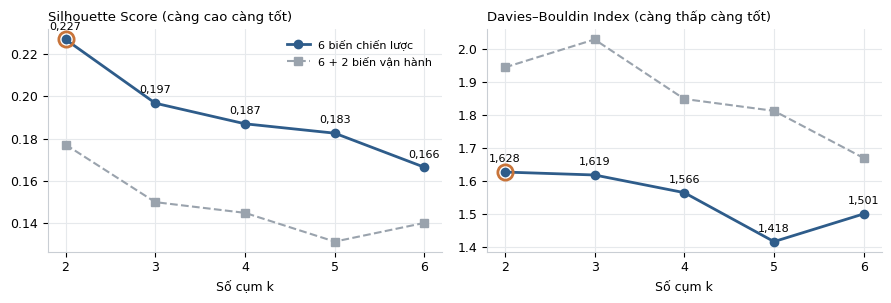

In [25]:
STRAT6 = ["Doanh_so_12_thang_tan", "Profitability_Gap_pct", "Cuong_do_canh_tranh_1_5",
          "Diem_du_an_ha_tang_khu_vuc_1_5", "Share_of_Wallet_pct", "Tang_truong_YoY_pct"]
OPS2 = ["Vong_quay_ton_kho_ngay", "Ty_le_cong_no_qua_han_pct"]

def scan_k(cols):
    Z = StandardScaler().fit_transform(df[cols]); rows = []
    for k in range(2, 7):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
        rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_),
                     "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                     "quy_mo_cum": sorted(np.bincount(km.labels_), reverse=True)})
    return pd.DataFrame(rows)

scan6, scan8 = scan_k(STRAT6), scan_k(STRAT6 + OPS2)
display(scan6.round(4)); display(scan8.round(4))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.1))
for ax, col, title in [(axs[0], "silhouette", "Silhouette Score (càng cao càng tốt)"),
                       (axs[1], "davies_bouldin", "Davies–Bouldin Index (càng thấp càng tốt)")]:
    ax.plot(scan6.k, scan6[col], "o-", color=BLUE, lw=2, label="6 biến chiến lược")
    ax.plot(scan8.k, scan8[col], "s--", color=GRAY, lw=1.5, label="6 + 2 biến vận hành")
    ax.plot(2, scan6[col][0], "o", ms=11, mfc="none", mec=ORANGE, mew=2)
    for x, v in zip(scan6.k, scan6[col]):
        ax.annotate(f"{v:.3f}".replace(".", ","), (x, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_title(title, loc="left", fontsize=9.5); ax.set_xlabel("Số cụm k"); ax.set_xticks(scan6.k)
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); save_fig(fig, "Hinh_5.1_Silhouette_DBI_theo_k"); plt.show()

In [26]:
K = 2   # Silhouette cao nhất; k = 5 có DBI thấp nhất nhưng Silhouette thấp hơn và cụm quá nhỏ
Z6 = StandardScaler().fit_transform(df[STRAT6])
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z6)
need_c = int(df.groupby(km.labels_)["Profitability_Gap_pct"].mean().idxmin())
df["Cluster_ID"] = np.where(km.labels_ == need_c, 1, 0)          # 1 = cần hỗ trợ
NAMES = {0: "Hiệu quả cao / thị trường thuận lợi", 1: "Cạnh tranh cao / cần hỗ trợ"}
df["Cluster_Name"] = df["Cluster_ID"].map(NAMES)
sil = silhouette_samples(Z6, km.labels_)
print("NPP Silhouette âm:", (sil < 0).sum(), "| NPP Silhouette < 0,05 (vùng ranh giới):", (sil < 0.05).sum())
display(df.groupby("Cluster_Name")[STRAT6 + [TARGET_RAW]].mean().round(2).T)
display(pd.crosstab(df.Cluster_Name, df.Vung_Mien))

NPP Silhouette âm: 3 | NPP Silhouette < 0,05 (vùng ranh giới): 19


Cluster_Name,Cạnh tranh cao / cần hỗ trợ,Hiệu quả cao / thị trường thuận lợi
Doanh_so_12_thang_tan,19912.11,26861.18
Profitability_Gap_pct,-1.46,0.85
Cuong_do_canh_tranh_1_5,3.81,2.63
Diem_du_an_ha_tang_khu_vuc_1_5,3.92,3.11
Share_of_Wallet_pct,44.36,48.74
Tang_truong_YoY_pct,24.60,17.10
Muc_rebate_hien_tai_VND_tan,43888.89,51570.18


Vung_Mien,Tây Nam Bộ (ĐBSCL),Đông Nam Bộ
Cluster_Name,,
Cạnh tranh cao / cần hỗ trợ,24,102
Hiệu quả cao / thị trường thuận lợi,87,27


## Bước C – Nhãn huấn luyện bằng Weighted Scoring / AHP (mục 5.4)
**C1. Chuẩn hóa 3 hướng** (về thang 0–1, điểm cao = càng được ưu tiên nhận rebate):
- benefit: x* = (x − min) / (max − min)
- cost: x* = (max − x) / (max − min)
- ideal-point (Price Index, mốc 1,0): x* = clip(1 − |x − 1| / dung sai, 0, 1), dung sai = phân vị 95% của |PI − 1|

In [27]:
CRIT = ["Profitability_Gap_pct", "Diem_du_an_ha_tang_khu_vuc_1_5", "Cuong_do_canh_tranh_1_5",
        "Share_of_Wallet_pct", "Doanh_so_12_thang_tan", "Price_Index", "Ty_le_cong_no_qua_han_pct"]
SHORT = dict(zip(CRIT, ["Profitability Gap", "Tiềm năng tăng trưởng", "Cường độ cạnh tranh",
                        "Share of Wallet", "Doanh số", "Price Index", "Công nợ quá hạn"]))
if MODE == "need":     # theo nhu cầu hỗ trợ (bản chính thức)
    DIRS = dict(zip(CRIT, ["cost", "benefit", "benefit", "benefit", "benefit", "ideal", "cost"]))
else:                  # đúng nhãn Bảng 4.1 bài giữa kỳ
    DIRS = dict(zip(CRIT, ["benefit", "benefit", "cost", "benefit", "benefit", "ideal", "cost"]))
TOL = round((df.Price_Index - 1).abs().quantile(0.95), 3)
print("Chiều chuẩn hóa:", DIRS); print("Dung sai Price Index =", TOL)

def normalize(s, d):
    if d == "benefit": return (s - s.min()) / (s.max() - s.min())
    if d == "cost":    return (s.max() - s) / (s.max() - s.min())
    return np.clip(1 - (s - 1.0).abs() / TOL, 0, 1)
N = pd.DataFrame({c: normalize(df[c], DIRS[c]) for c in CRIT})
N.describe().round(3)

Chiều chuẩn hóa: {'Profitability_Gap_pct': 'cost', 'Diem_du_an_ha_tang_khu_vuc_1_5': 'benefit', 'Cuong_do_canh_tranh_1_5': 'benefit', 'Share_of_Wallet_pct': 'benefit', 'Doanh_so_12_thang_tan': 'benefit', 'Price_Index': 'ideal', 'Ty_le_cong_no_qua_han_pct': 'cost'}
Dung sai Price Index = 0.027


,Profitability_Gap_pct,Diem_du_an_ha_tang_khu_vuc_1_5,Cuong_do_canh_tranh_1_5,Share_of_Wallet_pct,Doanh_so_12_thang_tan,Price_Index,Ty_le_cong_no_qua_han_pct
count,240.000,240.000,240.000,240.000,240.000,240.000,240.000
mean,0.447,0.634,0.563,0.433,0.209,0.564,0.792
std,0.203,0.200,0.231,0.196,0.152,0.308,0.152
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.299,0.525,0.419,0.288,0.105,0.296,0.744
50%,0.459,0.650,0.550,0.445,0.172,0.630,0.832
75%,0.602,0.775,0.725,0.564,0.272,0.815,0.901
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000


**C2. Trọng số AHP** – ma trận so sánh cặp theo thang Saaty, thứ tự ưu tiên: PG > Tăng trưởng > {Cạnh tranh = SOW} > Doanh số > {PI = Công nợ}. Trọng số = vector riêng ứng với trị riêng lớn nhất (chuẩn hóa tổng = 1). Kiểm tra nhất quán: CI = (λmax − n)/(n − 1), CR = CI / RI với RI(7) = 1,32; chấp nhận khi CR < 0,1.

In [28]:
lab = ["PG", "GR", "CT", "SOW", "DS", "PI", "CN"]
upper = {("PG","GR"):2, ("PG","CT"):2, ("PG","SOW"):2, ("PG","DS"):3, ("PG","PI"):6, ("PG","CN"):6,
         ("GR","CT"):1, ("GR","SOW"):1, ("GR","DS"):2, ("GR","PI"):4, ("GR","CN"):4,
         ("CT","SOW"):1, ("CT","DS"):2, ("CT","PI"):3, ("CT","CN"):3,
         ("SOW","DS"):2, ("SOW","PI"):3, ("SOW","CN"):3, ("DS","PI"):2, ("DS","CN"):2, ("PI","CN"):1}
M = np.ones((7, 7))
for (a, b), v in upper.items():
    i, j = lab.index(a), lab.index(b); M[i, j], M[j, i] = v, 1 / v
ev, evec = np.linalg.eig(M); i = int(np.argmax(ev.real)); lam = ev.real[i]
w = np.abs(evec[:, i].real); w = w / w.sum()
CI = (lam - 7) / 6; CR = CI / 1.32
W = dict(zip(CRIT, w))
display(pd.DataFrame(M, index=lab, columns=lab).round(3))
print(pd.Series({SHORT[c]: round(W[c], 3) for c in CRIT}))
print(f"λmax = {lam:.3f} | CI = {CI:.4f} | CR = {CR:.4f}  ->", "ĐẠT" if CR < 0.1 else "KHÔNG ĐẠT")

,PG,GR,CT,SOW,DS,PI,CN
PG,1.000,2.00,2.000,2.000,3.0,6.0,6.0
GR,0.500,1.00,1.000,1.000,2.0,4.0,4.0
CT,0.500,1.00,1.000,1.000,2.0,3.0,3.0
SOW,0.500,1.00,1.000,1.000,2.0,3.0,3.0
DS,0.333,0.50,0.500,0.500,1.0,2.0,2.0
PI,0.167,0.25,0.333,0.333,0.5,1.0,1.0
CN,0.167,0.25,0.333,0.333,0.5,1.0,1.0


Profitability Gap        0.310
Tiềm năng tăng trưởng    0.176
Cường độ cạnh tranh      0.162
Share of Wallet          0.162
Doanh số                 0.092
Price Index              0.050
Công nợ quá hạn          0.050
dtype: float64
λmax = 7.022 | CI = 0.0037 | CR = 0.0028  -> ĐẠT


**C3. Rebate Score và quy đổi sang VNĐ/tấn trong từng cụm** – Score(i) = Σ wⱼ × xᵢⱼ. Trong mỗi cụm: sàn = P10, trần = P90 của rebate hiện tại; Rebate đề xuất(i) = Sàn + PR(i | cụm) × (Trần − Sàn), với PR là thứ hạng phần trăm của Score trong cụm.

In [29]:
df["Rebate_Score"] = sum(N[c] * W[c] for c in CRIT)
contrib = pd.DataFrame({c: N[c] * W[c] for c in CRIT})
df["Top_factor"] = contrib.idxmax(axis=1).map(SHORT)
bounds = {}
for c, g in df.groupby("Cluster_ID"):
    lo, hi = g[TARGET_RAW].quantile(0.10), g[TARGET_RAW].quantile(0.90); bounds[c] = (lo, hi)
    pr = (g["Rebate_Score"].rank(method="average") - 1) / (len(g) - 1)
    df.loc[g.index, "Rebate_AHP_VND_tan"] = ((lo + pr * (hi - lo)) / 100).round() * 100
print(df.Rebate_Score.describe().round(3))
display(pd.DataFrame({NAMES[c]: {"Sàn P10": b[0], "Trần P90": b[1]} for c, b in bounds.items()}).T)
display(df.groupby("Cluster_Name")[["Rebate_Score", TARGET_RAW, "Rebate_AHP_VND_tan"]].mean().round(3))

count    240.000
mean       0.497
std        0.104
min        0.174
25%        0.427
50%        0.500
75%        0.573
max        0.752
Name: Rebate_Score, dtype: float64


,Sàn P10,Trần P90
Hiệu quả cao / thị trường thuận lợi,33300.0,70000.0
Cạnh tranh cao / cần hỗ trợ,25500.0,64500.0


,Rebate_Score,Muc_rebate_hien_tai_VND_tan,Rebate_AHP_VND_tan
Cluster_Name,,,
Cạnh tranh cao / cần hỗ trợ,0.560,43888.889,45000.0
Hiệu quả cao / thị trường thuận lợi,0.428,51570.175,51650.0


## Bước D – Tầng 2: Chia dữ liệu, tinh chỉnh và so sánh 3 mô hình (mục 5.5)
**Cách chia dữ liệu:** tách **20% (48 NPP) làm tập kiểm tra** ngay từ đầu (không đụng tới cho đến cuối). 80% còn lại (192 NPP) dùng **5-fold Cross-Validation lặp 10 lần** để tinh chỉnh siêu tham số và chọn mô hình. Cả hai lần chia đều phân tầng theo cụm. `StandardScaler` nằm trong `Pipeline` nên được fit lại trong từng fold → không rò rỉ thông tin.

Vì sao không chia 60/20/20 một lần? Với 240 NPP, tập Validation chỉ có 48 NPP nên kết quả phụ thuộc nhiều vào may rủi khi chia (ô cuối của Bước D minh họa điều này).

In [30]:
X = df[FEATS11].copy()
X["Loai_NPP_TongDaiLy"] = (df["Loai_NPP"] == "Tổng đại lý").astype(int)
X["Cluster_1_CanHoTro"] = df["Cluster_ID"]
y = df["Rebate_AHP_VND_tan"].values
strat = df["Cluster_ID"].values
i_tv, i_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=strat, random_state=SEED)
print("Huấn luyện:", len(i_tv), "| Kiểm tra:", len(i_te),
      "| Tỷ lệ nhóm cần hỗ trợ:", round(strat[i_tv].mean(), 3), round(strat[i_te].mean(), 3))

def make(name, p):
    m = (Ridge(**p) if name == "Ridge" else
         RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **p) if name == "Random Forest" else
         GradientBoostingRegressor(random_state=SEED, **p))
    return make_pipeline(StandardScaler(), m)

KF, REPS = 5, 10
splits = list(RepeatedStratifiedKFold(n_splits=KF, n_repeats=REPS, random_state=SEED).split(i_tv, strat[i_tv]))
def cv_eval(name, p):
    r, mae, r2 = [], [], []
    for tr, va in splits:
        a, b = i_tv[tr], i_tv[va]
        pr = make(name, p).fit(X.iloc[a], y[a]).predict(X.iloc[b])
        r.append(rmse(y[b], pr)); mae.append(mean_absolute_error(y[b], pr)); r2.append(r2_score(y[b], pr))
    r = np.array(r)
    return dict(rmse=r.mean(), se=r.std(ddof=1) / np.sqrt(KF), mae=np.mean(mae), r2=np.mean(r2),
                rep_min=r.reshape(REPS, KF).mean(1).min(), rep_max=r.reshape(REPS, KF).mean(1).max())

Huấn luyện: 192 | Kiểm tra: 48 | Tỷ lệ nhóm cần hỗ trợ: 0.526 0.521


In [31]:
grids = {
    "Ridge": [{"alpha": a} for a in [0.01, 0.1, 1, 3, 10, 30, 100]],
    "Random Forest": [{"max_depth": d, "min_samples_leaf": l} for d in [3, 5, 8, None] for l in [1, 3, 5]],
    "Gradient Boosting": [{"max_depth": d, "learning_rate": lr, "n_estimators": n}
                          for d in [2, 3] for lr in [0.05, 0.1] for n in [100, 300]],
}
tuning, best = {}, {}
for name, grid in grids.items():                 # ~5 phút, Random Forest lâu nhất
    t = pd.DataFrame([{"params": str(p), **cv_eval(name, p)} for p in grid])
    tuning[name] = t
    best[name] = grid[int(t.rmse.idxmin())]
    print(f"\n=== Tinh chỉnh {name} ==="); display(t.round(3))


=== Tinh chỉnh Ridge ===


,params,rmse,se,mae,r2,rep_min,rep_max
0,{'alpha': 0.01},2858.755,229.092,2201.917,0.937,2762.673,2950.644
1,{'alpha': 0.1},2858.822,227.736,2204.745,0.937,2762.945,2950.526
2,{'alpha': 1},2868.958,214.470,2239.559,0.937,2776.720,2957.816
3,{'alpha': 3},2940.688,188.760,2348.446,0.934,2863.270,3019.239
4,{'alpha': 10},3434.382,159.032,2851.913,0.911,3370.820,3510.669
5,{'alpha': 30},4840.967,211.282,4079.458,0.825,4774.373,4932.092
6,{'alpha': 100},7105.205,263.112,6035.051,0.625,7029.911,7189.611



=== Tinh chỉnh Random Forest ===


,params,rmse,se,mae,r2,rep_min,rep_max
0,"{'max_depth': 3, 'min_samples_leaf': 1}",8360.774,335.280,7071.103,0.481,8196.136,8709.588
1,"{'max_depth': 3, 'min_samples_leaf': 3}",8380.363,337.377,7078.785,0.479,8211.210,8728.649
2,"{'max_depth': 3, 'min_samples_leaf': 5}",8423.290,338.086,7115.878,0.473,8244.346,8770.851
3,"{'max_depth': 5, 'min_samples_leaf': 1}",7466.782,325.548,6266.584,0.585,7255.043,7731.763
4,"{'max_depth': 5, 'min_samples_leaf': 3}",7517.240,326.317,6284.909,0.579,7312.245,7755.564
5,"{'max_depth': 5, 'min_samples_leaf': 5}",7715.767,327.498,6451.921,0.557,7508.988,7982.819
6,"{'max_depth': 8, 'min_samples_leaf': 1}",7227.113,324.746,6062.588,0.611,6962.444,7469.529
7,"{'max_depth': 8, 'min_samples_leaf': 3}",7340.819,328.766,6124.655,0.598,7105.607,7553.846
8,"{'max_depth': 8, 'min_samples_leaf': 5}",7630.270,327.427,6373.512,0.566,7415.131,7877.675
9,"{'max_depth': None, 'min_samples_leaf': 1}",7216.717,325.122,6049.419,0.612,6968.574,7471.650



=== Tinh chỉnh Gradient Boosting ===


,params,rmse,se,mae,r2,rep_min,rep_max
0,"{'max_depth': 2, 'learning_rate': 0.05, 'n_est...",6138.165,269.354,5027.088,0.719,5929.745,6433.276
1,"{'max_depth': 2, 'learning_rate': 0.05, 'n_est...",4953.993,269.771,3974.762,0.816,4639.076,5277.391
2,"{'max_depth': 2, 'learning_rate': 0.1, 'n_esti...",5257.966,285.316,4238.172,0.793,4947.443,5499.516
3,"{'max_depth': 2, 'learning_rate': 0.1, 'n_esti...",4709.658,279.556,3755.757,0.833,4273.698,4917.447
4,"{'max_depth': 3, 'learning_rate': 0.05, 'n_est...",5820.880,316.237,4729.476,0.746,5466.101,6107.853
5,"{'max_depth': 3, 'learning_rate': 0.05, 'n_est...",5243.687,306.660,4219.197,0.793,4966.991,5524.903
6,"{'max_depth': 3, 'learning_rate': 0.1, 'n_esti...",5354.133,318.391,4293.392,0.785,5043.756,5585.181
7,"{'max_depth': 3, 'learning_rate': 0.1, 'n_esti...",5200.985,320.554,4170.120,0.797,4898.632,5423.445


Đã lưu hình: hinh_anh_muc5_need/Hinh_5.3_Tinh_chinh_Ridge_alpha.png


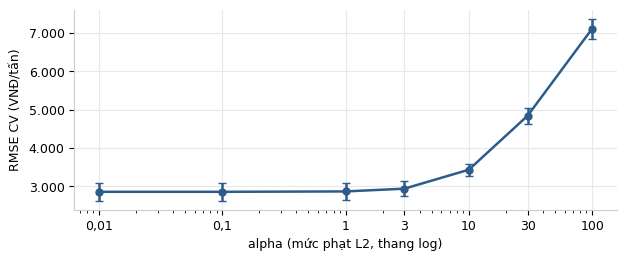

In [32]:
# Hình 5.3 – RMSE CV của Ridge theo alpha
t = tuning["Ridge"].copy(); t["alpha"] = [p["alpha"] for p in grids["Ridge"]]
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.errorbar(t.alpha, t.rmse, yerr=t.se, color=BLUE, marker="o", ms=5, lw=1.8, capsize=3)
ax.set_xscale("log"); ax.set_xticks(t.alpha); ax.set_xticklabels([f"{a:g}".replace(".", ",") for a in t.alpha])
ax.yaxis.set_major_formatter(VN); ax.set_xlabel("alpha (mức phạt L2, thang log)"); ax.set_ylabel("RMSE CV (VNĐ/tấn)")
save_fig(fig, "Hinh_5.3_Tinh_chinh_Ridge_alpha"); plt.show()

,params,rmse,se,mae,r2,rep_min,rep_max
model,,,,,,,
Ridge,{'alpha': 0.01},2858.755,229.092,2201.917,0.937,2762.673,2950.644
Random Forest,"{'max_depth': None, 'min_samples_leaf': 1}",7216.717,325.122,6049.419,0.612,6968.574,7471.650
Gradient Boosting,"{'max_depth': 2, 'learning_rate': 0.1, 'n_esti...",4709.658,279.556,3755.757,0.833,4273.698,4917.447


Mô hình tốt nhất: Ridge | Ngưỡng one-SE = 3,087.8 | Mô hình được chọn: Ridge
Đã lưu hình: hinh_anh_muc5_need/Hinh_5.4_So_sanh_3_mo_hinh_one_SE.png


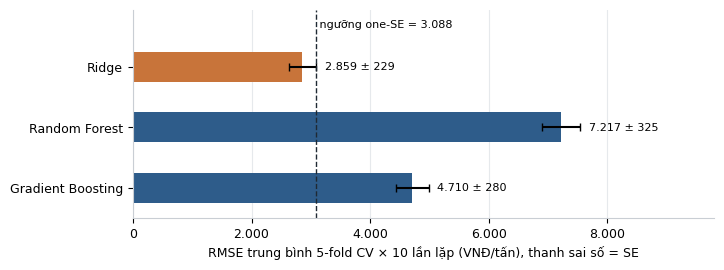

In [33]:
cmp = pd.DataFrame([{"model": n, "params": str(best[n]),
                     **tuning[n].loc[tuning[n].rmse.idxmin(), ["rmse", "se", "mae", "r2", "rep_min", "rep_max"]].to_dict()}
                    for n in grids]).set_index("model")
display(cmp.round(3))
b = cmp.rmse.idxmin(); thr = cmp.loc[b, "rmse"] + cmp.loc[b, "se"]
order = ["Ridge", "Random Forest", "Gradient Boosting"]          # độ phức tạp tăng dần
chosen = next(m for m in order if cmp.loc[m, "rmse"] <= thr)
print(f"Mô hình tốt nhất: {b} | Ngưỡng one-SE = {thr:,.1f} | Mô hình được chọn: {chosen}")
fig, ax = plt.subplots(figsize=(7.5, 2.7))
ax.barh(cmp.index, cmp.rmse, xerr=cmp.se, height=0.5, capsize=3,
        color=[ORANGE if m == chosen else BLUE for m in cmp.index])
ax.axvline(thr, ls="--", color=INK, lw=1)
ax.text(thr, -0.62, f" ngưỡng one-SE = {thr:,.0f}".replace(",", "."), fontsize=8, va="bottom")
for k, (v, s) in enumerate(zip(cmp.rmse, cmp.se)):
    ax.text(v + s + cmp.rmse.max() * 0.02, k, f"{v:,.0f} ± {s:,.0f}".replace(",", "."), va="center", fontsize=8)
ax.set_ylim(2.5, -0.95); ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(VN)
ax.set_xlim(0, (cmp.rmse + cmp.se).max() * 1.3)
ax.set_xlabel("RMSE trung bình 5-fold CV × 10 lần lặp (VNĐ/tấn), thanh sai số = SE")
save_fig(fig, "Hinh_5.4_So_sanh_3_mo_hinh_one_SE"); plt.show()

In [34]:
# Đánh giá MỘT lần trên tập kiểm tra sau khi huấn luyện lại trên toàn bộ 192 NPP
final_pipe = make(chosen, best[chosen]).fit(X.iloc[i_tv], y[i_tv])
pt = final_pipe.predict(X.iloc[i_te])
boot = [rmse(y[i_te][s], pt[s]) for s in (rng.integers(0, len(i_te), len(i_te)) for _ in range(2000))]
print(f"Test RMSE = {rmse(y[i_te], pt):,.1f}  (CI90% bootstrap: {np.percentile(boot, 5):,.0f} – {np.percentile(boot, 95):,.0f})")
print(f"Test MAE  = {mean_absolute_error(y[i_te], pt):,.1f} | Test R² = {r2_score(y[i_te], pt):.3f}")
print(f"Tham chiếu – dự đoán bằng trung bình: RMSE = {rmse(y[i_te], np.full(len(i_te), y[i_tv].mean())):,.1f}")

Test RMSE = 3,080.3  (CI90% bootstrap: 2,002 – 4,254)
Test MAE  = 2,072.4 | Test R² = 0.915
Tham chiếu – dự đoán bằng trung bình: RMSE = 10,574.0


200 lần chia 1 lần: min 2,029 | P5 2,325 | trung vị 2,822 | P95 3,634 | max 4,347
5-fold CV × 10: 2,859 (dao động giữa các lần lặp 2,763 – 2,951)
Đã lưu hình: hinh_anh_muc5_need/Hinh_5.2_Do_dao_dong_chia_1_lan_vs_CV.png


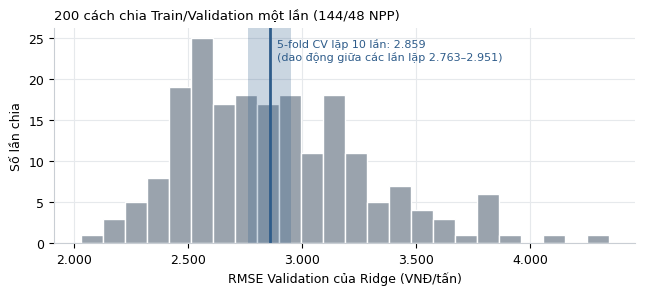

In [35]:
# Minh họa: nếu chỉ chia Train/Validation MỘT lần (144/48), RMSE dao động bao nhiêu tùy cách chia?
ss = []
for s in range(200):
    a, bb = train_test_split(i_tv, test_size=48, stratify=strat[i_tv], random_state=s)
    ss.append(rmse(y[bb], make("Ridge", best["Ridge"]).fit(X.iloc[a], y[a]).predict(X.iloc[bb])))
ss = np.array(ss)
print(f"200 lần chia 1 lần: min {ss.min():,.0f} | P5 {np.percentile(ss,5):,.0f} | trung vị {np.median(ss):,.0f} | P95 {np.percentile(ss,95):,.0f} | max {ss.max():,.0f}")
print(f"5-fold CV × 10: {cmp.loc['Ridge','rmse']:,.0f} (dao động giữa các lần lặp {cmp.loc['Ridge','rep_min']:,.0f} – {cmp.loc['Ridge','rep_max']:,.0f})")
r = cmp.loc["Ridge"]
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.hist(ss, bins=24, color=GRAY, edgecolor="white")
ax.axvspan(r.rep_min, r.rep_max, color=BLUE, alpha=0.25, lw=0)
ax.axvline(r.rmse, color=BLUE, lw=2)
ax.text(r.rmse, ax.get_ylim()[1] * 0.95, (f"  5-fold CV lặp 10 lần: {r.rmse:,.0f}\n"
        f"  (dao động giữa các lần lặp {r.rep_min:,.0f}–{r.rep_max:,.0f})").replace(",", "."), color=BLUE, fontsize=8, va="top")
ax.xaxis.set_major_formatter(VN); ax.set_xlabel("RMSE Validation của Ridge (VNĐ/tấn)"); ax.set_ylabel("Số lần chia")
ax.set_title("200 cách chia Train/Validation một lần (144/48 NPP)", loc="left", fontsize=9.5)
save_fig(fig, "Hinh_5.2_Do_dao_dong_chia_1_lan_vs_CV"); plt.show()

## Bước E – Diễn giải mô hình và đối chiếu AHP (mục 5.5.5)
Với Ridge, mức độ quan trọng = **hệ số chuẩn hóa** (thay đổi rebate dự đoán khi biến tăng 1 độ lệch chuẩn). Nếu mô hình cây được chọn thì dùng `feature_importances_`. So sánh thứ hạng với trọng số AHP bằng hệ số Spearman.
⚠️ Nhãn được tạo từ chính 7 tiêu chí AHP → độ khớp cao chỉ là **kiểm tra nhất quán nội tại**, không phải bằng chứng độc lập.

,Hệ số chuẩn hóa
Cluster_1_CanHoTro,-12656.9
Profitability_Gap_pct,-9033.9
Cuong_do_canh_tranh_1_5,4859.8
Diem_du_an_ha_tang_khu_vuc_1_5,4856.5
Share_of_Wallet_pct,4566.0
Doanh_so_12_thang_tan,2182.2
Price_Index,734.2
Ty_le_cong_no_qua_han_pct,-652.2
So_nam_hop_tac,267.1
Vong_quay_ton_kho_ngay,236.0


,Trọng số AHP,Tỷ trọng từ mô hình,Hạng AHP,Hạng mô hình
Profitability Gap,0.310,0.336,1,1
Tiềm năng tăng trưởng,0.176,0.181,2,3
Cường độ cạnh tranh,0.162,0.181,3,2
Share of Wallet,0.162,0.170,3,4
Doanh số,0.092,0.081,5,5
Price Index,0.050,0.027,6,6
Công nợ quá hạn,0.050,0.024,6,7


Spearman ρ = 0.927
Đã lưu hình: hinh_anh_muc5_need/Hinh_5.5_Doi_chieu_AHP_mo_hinh.png


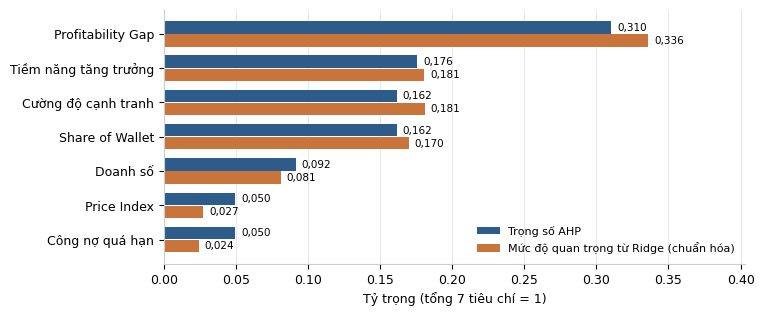

In [36]:
model = final_pipe[-1]
imp = pd.Series(np.abs(model.coef_) if chosen == "Ridge" else model.feature_importances_, index=X.columns)
if chosen == "Ridge":
    display(pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False).round(1).to_frame("Hệ số chuẩn hóa"))
imp7 = imp[CRIT] / imp[CRIT].sum()
tri = pd.DataFrame({"Trọng số AHP": [W[c] for c in CRIT], "Tỷ trọng từ mô hình": imp7.values},
                   index=[SHORT[c] for c in CRIT])
tri["Hạng AHP"] = tri["Trọng số AHP"].rank(ascending=False, method="min").astype(int)
tri["Hạng mô hình"] = tri["Tỷ trọng từ mô hình"].rank(ascending=False).astype(int)
display(tri.round(3))
print("Spearman ρ =", round(spearmanr(tri["Trọng số AHP"], tri["Tỷ trọng từ mô hình"]).correlation, 3))
fig, ax = plt.subplots(figsize=(7.5, 3.3)); yy = np.arange(len(tri))
ax.barh(yy - 0.19, tri["Trọng số AHP"], height=0.36, color=BLUE, label="Trọng số AHP")
ax.barh(yy + 0.19, tri["Tỷ trọng từ mô hình"], height=0.36, color=ORANGE, label=f"Mức độ quan trọng từ {chosen} (chuẩn hóa)")
for k, (a, b) in enumerate(zip(tri["Trọng số AHP"], tri["Tỷ trọng từ mô hình"])):
    ax.text(a + 0.004, k - 0.19, f"{a:.3f}".replace(".", ","), va="center", fontsize=7.5)
    ax.text(b + 0.004, k + 0.19, f"{b:.3f}".replace(".", ","), va="center", fontsize=7.5)
ax.set_yticks(yy); ax.set_yticklabels(tri.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, tri[["Trọng số AHP", "Tỷ trọng từ mô hình"]].values.max() * 1.2)
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_xlabel("Tỷ trọng (tổng 7 tiêu chí = 1)")
save_fig(fig, "Hinh_5.5_Doi_chieu_AHP_mo_hinh"); plt.show()

## Bước F – Ngân sách, 10 NPP điển hình và xuất kết quả (mục 5.6)
Tổng ngân sách = Σ (rebate × sản lượng 12 tháng). Khoảng Min–Max = dự đoán của mô hình ± RMSE kiểm tra.

In [37]:
test_rmse = rmse(y[i_te], pt)
df["Rebate_ML_VND_tan"] = (final_pipe.predict(X) / 100).round() * 100
df["Rebate_Min"] = ((df.Rebate_ML_VND_tan - test_rmse) / 1000).round() * 1000
df["Rebate_Max"] = ((df.Rebate_ML_VND_tan + test_rmse) / 1000).round() * 1000
vol = df["Doanh_so_12_thang_tan"]
bud = pd.Series({"Hiện tại": (df[TARGET_RAW] * vol).sum(), "Đề xuất AHP": (df.Rebate_AHP_VND_tan * vol).sum(),
                 "Dự đoán mô hình": (df.Rebate_ML_VND_tan * vol).sum()}) / 1e9
print("Tổng ngân sách (tỷ VNĐ/năm):"); print(bud.round(2))
print("Thay đổi AHP: %.2f%%" % ((bud["Đề xuất AHP"] / bud["Hiện tại"] - 1) * 100))
grp = np.where(df.Profitability_Gap_pct < 0, "PG < 0 (thiệt thòi)", "PG ≥ 0 (đã lời)")
display(df.groupby(grp)[[TARGET_RAW, "Rebate_AHP_VND_tan"]].mean().round(0))
print("Tương quan rebate mới với Doanh số / PG / Cạnh tranh:",
      [round(float(df.Rebate_AHP_VND_tan.corr(df[c])), 3) for c in ["Doanh_so_12_thang_tan", "Profitability_Gap_pct", "Cuong_do_canh_tranh_1_5"]],
      "| rebate hiện tại:", [round(float(df[TARGET_RAW].corr(df[c])), 3) for c in ["Doanh_so_12_thang_tan", "Profitability_Gap_pct", "Cuong_do_canh_tranh_1_5"]])

Tổng ngân sách (tỷ VNĐ/năm):
Hiện tại           304.81
Đề xuất AHP        283.00
Dự đoán mô hình    283.06
dtype: float64
Thay đổi AHP: -7.16%


,Muc_rebate_hien_tai_VND_tan,Rebate_AHP_VND_tan
PG < 0 (thiệt thòi),46804.0,50476.0
PG ≥ 0 (đã lời),48529.0,45024.0


Tương quan rebate mới với Doanh số / PG / Cạnh tranh: [0.394, -0.386, 0.261] | rebate hiện tại: [0.836, 0.023, -0.059]


In [38]:
FOCUS = ["NPP_193", "NPP_041", "NPP_155", "NPP_098", "NPP_072", "NPP_021", "NPP_186", "NPP_202", "NPP_042", "NPP_077"]
cols = ["NPP_ID", "Cluster_Name", "Profitability_Gap_pct", "Cuong_do_canh_tranh_1_5", TARGET_RAW,
        "Rebate_AHP_VND_tan", "Rebate_ML_VND_tan", "Rebate_Min", "Rebate_Max", "Top_factor"]
f = df.set_index("NPP_ID").loc[FOCUS].reset_index()[cols]
f["Thay_doi_AHP"] = f.Rebate_AHP_VND_tan - f[TARGET_RAW]
f

,NPP_ID,Cluster_Name,Profitability_Gap_pct,Cuong_do_canh_tranh_1_5,Muc_rebate_hien_tai_VND_tan,Rebate_AHP_VND_tan,Rebate_ML_VND_tan,Rebate_Min,Rebate_Max,Top_factor,Thay_doi_AHP
0,NPP_193,Cạnh tranh cao / cần hỗ trợ,-5.50,5.0,22000,61100.0,60400.0,57000.0,63000.0,Profitability Gap,39100.0
1,NPP_041,Cạnh tranh cao / cần hỗ trợ,-4.38,4.1,60000,60100.0,61100.0,58000.0,64000.0,Profitability Gap,100.0
2,NPP_155,Cạnh tranh cao / cần hỗ trợ,-4.05,3.9,43000,53600.0,53800.0,51000.0,57000.0,Profitability Gap,10600.0
3,NPP_098,Cạnh tranh cao / cần hỗ trợ,-3.93,4.5,58000,64200.0,65600.0,63000.0,69000.0,Profitability Gap,6200.0
4,NPP_072,Cạnh tranh cao / cần hỗ trợ,-3.87,4.0,39000,39900.0,42400.0,39000.0,45000.0,Profitability Gap,900.0
5,NPP_021,Hiệu quả cao / thị trường thuận lợi,1.74,3.2,81000,62500.0,62200.0,59000.0,65000.0,Tiềm năng tăng trưởng,-18500.0
6,NPP_186,Hiệu quả cao / thị trường thuận lợi,0.98,3.1,79000,50200.0,48100.0,45000.0,51000.0,Profitability Gap,-28800.0
7,NPP_202,Hiệu quả cao / thị trường thuận lợi,0.75,2.6,78000,66400.0,64400.0,61000.0,67000.0,Share of Wallet,-11600.0
8,NPP_042,Hiệu quả cao / thị trường thuận lợi,1.68,2.2,77000,42700.0,41600.0,39000.0,45000.0,Share of Wallet,-34300.0
9,NPP_077,Hiệu quả cao / thị trường thuận lợi,0.44,3.1,76000,59300.0,60200.0,57000.0,63000.0,Tiềm năng tăng trưởng,-16700.0


Đã lưu hình: hinh_anh_muc5_need/Hinh_5.6_Rebate_10_NPP_dien_hinh.png


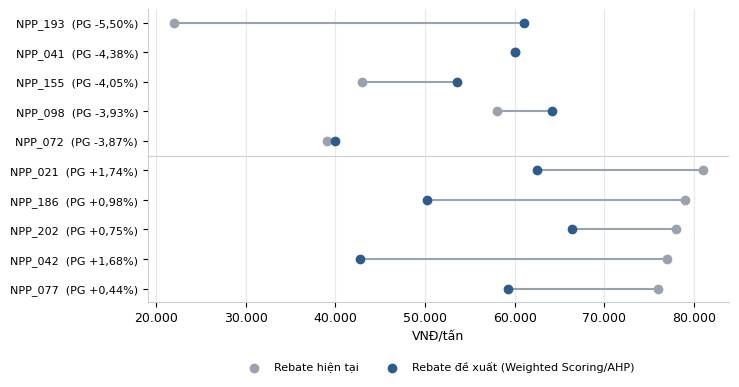

In [39]:
# Hình 5.6 – Rebate hiện tại và rebate đề xuất của 10 NPP điển hình
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, row in f.iterrows():
    ax.plot([row[TARGET_RAW], row.Rebate_AHP_VND_tan], [k, k], color=GRAY, lw=1.5, zorder=1)
ax.scatter(f[TARGET_RAW], range(len(f)), color=GRAY, s=36, zorder=2, label="Rebate hiện tại")
ax.scatter(f.Rebate_AHP_VND_tan, range(len(f)), color=BLUE, s=36, zorder=3, label="Rebate đề xuất (Weighted Scoring/AHP)")
ax.set_yticks(range(len(f)))
ax.set_yticklabels([f"{a}  (PG {p:+.2f}%)".replace(".", ",") for a, p in zip(f.NPP_ID, f.Profitability_Gap_pct)], fontsize=8)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.axhline(4.5, color="#C9CED4", lw=0.8)
ax.xaxis.set_major_formatter(VN); ax.set_xlabel("VNĐ/tấn")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
save_fig(fig, "Hinh_5.6_Rebate_10_NPP_dien_hinh"); plt.show()

In [40]:
out_cols = ["NPP_ID", "Tinh_Thanh", "Vung_Mien", "Cluster_Name", TARGET_RAW, "Rebate_Score",
            "Rebate_AHP_VND_tan", "Rebate_ML_VND_tan", "Rebate_Min", "Rebate_Max", "Top_factor"]
fname = f"rebate_recommendation_output_{MODE}.csv"
df[out_cols].to_csv(fname, index=False, encoding="utf-8-sig")
print("Đã lưu", fname)
try:
    from google.colab import files; files.download(fname)
except ImportError:
    pass
print("\nCác hình đã lưu trong", f"hinh_anh_muc5_{MODE}/:")
for fn in sorted(os.listdir(f"hinh_anh_muc5_{MODE}")): print("  -", fn)

Đã lưu rebate_recommendation_output_need.csv

Các hình đã lưu trong hinh_anh_muc5_need/:
  - Hinh_5.1_Silhouette_DBI_theo_k.png
  - Hinh_5.2_Do_dao_dong_chia_1_lan_vs_CV.png
  - Hinh_5.3_Tinh_chinh_Ridge_alpha.png
  - Hinh_5.4_So_sanh_3_mo_hinh_one_SE.png
  - Hinh_5.5_Doi_chieu_AHP_mo_hinh.png
  - Hinh_5.6_Rebate_10_NPP_dien_hinh.png


## Bước G – Kiểm tra độ nhạy theo chiều chuẩn hóa (mục 5.7)
Đổi `MODE = "health"` ở Bước 0 rồi `Runtime → Run all` để chạy với nhãn Benefit/Cost của bài giữa kỳ. Kết quả kỳ vọng (so với bản chính thức `need`):

| Chỉ tiêu | health (nhãn giữa kỳ) | need (chính thức) |
|---|---|---|
| Tương quan rebate mới – Profitability Gap | +0,769 | −0,386 |
| Rebate TB nhóm PG < 0 (hiện tại 46.804) | 42.063 | 50.476 |
| NPP_193 (hiện tại 22.000) | 25.500 | 61.100 |
| Thay đổi ngân sách | −10,05% | −7,16% |

## Kết quả kỳ vọng với MODE = "need" (để đối chiếu)
11 biến (VIF max 3,07) · k = 2, Silhouette 0,2269 · AHP CR = 0,0028 · Ridge alpha 0,01, RMSE CV 2.859 ± 229 (RF 7.217, GB 4.709) · Test RMSE 3.080, R² 0,915 · Spearman 0,927 · Ngân sách −7,16%.